# FASE 6 — Modelo de Latencia

En las fases anteriores incorporamos:

- Bid y Ask.
- Spread.
- Filtro de spread.
- Slippage.

Ahora incorporaremos la latencia.

La latencia representa el tiempo transcurrido entre:

1. el momento en que el sistema decide ejecutar una orden;
2. el momento en que esa orden puede alcanzar realmente el mercado.

Ejemplo:

Decisión:

`10:00:00.000`

Latencia:

`150 ms`

Momento mínimo de ejecución:

`10:00:00.150`

Durante esos 150 milisegundos el Bid y Ask pueden cambiar.

Por tanto, la latencia no es directamente un coste expresado en puntos.

Es un retraso temporal que puede producir una diferencia de precio.

En esta fase utilizaremos los ticks históricos para localizar el primer
tick disponible después del retraso simulado.

IMPORTANTE:

Todavía no estamos midiendo la latencia real de nuestro broker.

Los escenarios LOW, BASE y STRESS serán hipótesis de simulación.

Más adelante, durante el forward test en MT5, registraremos latencia
y slippage reales.

## 1. Configuración

Utilizamos nuevamente la base limpia de ticks creada en la Fase 3.

La resolución temporal de los ticks nos permitirá simular qué precio
habría estado disponible después de un determinado retraso.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------------
# CONFIGURACIÓN
# --------------------------------------------------

DATA_PROCESSED = Path("../data/processed")

SNAPSHOT_DATE = "20260908"

TICKS_FILE = (
    DATA_PROCESSED
    / f"eurusd_ticks_clean_{SNAPSHOT_DATE}.parquet"
)


POINT = 0.00001

POINTS_PER_PIP = 10


print("Archivo:")
print(TICKS_FILE.resolve())

print("\nPOINT:", POINT)

print(
    "Puntos por pip:",
    POINTS_PER_PIP
)

Archivo:
C:\ALL\TECNICO\TRADING\CURSOS\TUTORIAS\PROYECTO2\mt5_microstructure_lab\data\processed\eurusd_ticks_clean_20260908.parquet

POINT: 1e-05
Puntos por pip: 10


## 2. Cargar los datos

Cargamos los ticks procesados y verificamos que estén ordenados
cronológicamente.

El orden temporal es indispensable para poder buscar qué tick habría
estado disponible después de una determinada latencia.

In [2]:
if not TICKS_FILE.exists():

    raise FileNotFoundError(
        "No existe el archivo procesado.\n"
        "Ejecute primero las fases anteriores.\n\n"
        f"{TICKS_FILE.resolve()}"
    )


ticks = pd.read_parquet(
    TICKS_FILE
)


ticks["time"] = pd.to_datetime(
    ticks["time"],
    utc=True
)


ticks = (
    ticks
    .reset_index(drop=True)
)


print(
    "Número de ticks:",
    len(ticks)
)

print(
    "Primer tick:",
    ticks["time"].min()
)

print(
    "Último tick:",
    ticks["time"].max()
)

print(
    "Orden cronológico:",
    ticks["time"].is_monotonic_increasing
)


assert (
    ticks["time"].is_monotonic_increasing
)

Número de ticks: 1064157
Primer tick: 2026-09-01 00:17:05.574000+00:00
Último tick: 2026-09-08 00:16:56.458000+00:00
Orden cronológico: True


## 3. Preparar la base de ejecución

Añadiremos:

- identificador único de tick;
- mid-price;
- representación temporal en nanosegundos.

La representación en nanosegundos permitirá localizar rápidamente
el primer tick posterior al tiempo objetivo de ejecución.

In [3]:
ticks_exec = (
    ticks
    .copy()
)


ticks_exec["tick_id"] = np.arange(
    len(ticks_exec)
)


ticks_exec["mid_price"] = (
    ticks_exec["bid"]
    +
    ticks_exec["ask"]
) / 2


# --------------------------------------------------
# IMPORTANTE:
# Convertimos explícitamente el tiempo a nanosegundos
# antes de obtener su representación numérica.
# --------------------------------------------------

time_ns = (
    ticks_exec["time"]
    .astype("datetime64[ns, UTC]")
    .array
    .asi8
)


spread_p99 = float(
    ticks_exec[
        "spread_points"
    ]
    .quantile(0.99)
)


# Evitamos pequeñas diferencias producidas
# por representación de punto flotante.
spread_p99 = round(
    spread_p99,
    6
)


MAX_ENTRY_SPREAD_POINTS = (
    spread_p99
)


print(
    "Tipo temporal original:",
    ticks_exec["time"].dtype
)

print(
    "Primer timestamp entero en ns:",
    time_ns[0]
)

print(
    "P99 spread:",
    spread_p99
)

print(
    "Límite provisional de spread:",
    MAX_ENTRY_SPREAD_POINTS
)

Tipo temporal original: datetime64[ms, UTC]
Primer timestamp entero en ns: 1788221825574000000
P99 spread: 2.0
Límite provisional de spread: 2.0


## 4. Tiempo entre ticks

Antes de modelar latencia debemos conocer aproximadamente con qué
frecuencia llegan los ticks.

Calcularemos el tiempo transcurrido entre observaciones consecutivas.

Puede haber diferencias iguales a cero porque en fases anteriores
comprobamos que existen timestamps repetidos con información distinta.

Estos registros no fueron eliminados.

In [4]:
ticks_exec[
    "intertick_ms"
] = (
    ticks_exec["time"]
    .diff()
    .dt.total_seconds()
    * 1000
)


same_time_transitions = int(
    (
        ticks_exec[
            "intertick_ms"
        ]
        ==
        0
    ).sum()
)


positive_intertick = (
    ticks_exec.loc[
        ticks_exec[
            "intertick_ms"
        ]
        >
        0,
        "intertick_ms"
    ]
)


print(
    "Transiciones con mismo timestamp:",
    same_time_transitions
)

print(
    "Intervalos temporales positivos:",
    len(positive_intertick)
)

Transiciones con mismo timestamp: 3255
Intervalos temporales positivos: 1060901


In [5]:
intertick_percentiles = (
    positive_intertick
    .quantile(
        [
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.999,
            1.00
        ]
    )
    .rename(
        "intertick_ms"
    )
    .to_frame()
)


display(
    intertick_percentiles
)

,intertick_ms
0.010,3.0
0.050,10.0
0.250,32.0
0.500,80.0
0.750,257.0
0.900,932.0
0.950,1768.0
0.990,5267.0
0.999,17113.3
1.000,172804430.0


Esto será interesante porque una latencia de 20 ms no tiene el mismo efecto en un mercado que recibe un tick cada 10 ms que en otro donde pasan 500 ms entre ticks.

## 5. Precio de mercado esperado

Mantenemos la misma regla de ejecución de las fases anteriores.

BUY:

abre comprando → Ask  
cierra vendiendo → Bid

SELL:

abre vendiendo → Bid  
cierra comprando → Ask

In [6]:
def expected_market_price(
    tick,
    action
):
    """
    Precio esperado de una orden de mercado
    sin latencia ni slippage.

    BUY  -> Ask
    SELL -> Bid
    """

    action = action.upper()


    if action == "BUY":

        return float(
            tick["ask"]
        )


    elif action == "SELL":

        return float(
            tick["bid"]
        )


    else:

        raise ValueError(
            "action debe ser BUY o SELL."
        )

## 6. Buscar el primer tick ejecutable después de la latencia

Supongamos:

Decisión:

`10:00:00.000`

Latencia:

`150 ms`

Tiempo objetivo:

`10:00:00.150`

Buscaremos el primer tick cuya hora sea:

`time >= 10:00:00.150`

Ese tick representará la primera cotización disponible para nuestro
modelo después del retraso.

Distinguiremos:

- latencia solicitada/simulada;
- retraso efectivo hasta el primer tick disponible.

El segundo puede ser mayor porque puede no existir un tick exactamente
en el instante objetivo.

In [7]:
def resolve_delayed_tick_id(
    time_ns_array,
    decision_tick_id,
    latency_ms
):
    """
    Devuelve el primer tick disponible después de:

    tiempo_decision + latency_ms

    Si no quedan datos suficientes devuelve None.
    """

    decision_tick_id = int(
        decision_tick_id
    )


    latency_ms = float(
        latency_ms
    )


    if decision_tick_id < 0:

        raise ValueError(
            "decision_tick_id no puede ser negativo."
        )


    if decision_tick_id >= len(
        time_ns_array
    ):

        raise ValueError(
            "decision_tick_id fuera del rango."
        )


    if latency_ms < 0:

        raise ValueError(
            "La latencia no puede ser negativa."
        )


    decision_time_ns = int(
        time_ns_array[
            decision_tick_id
        ]
    )


    latency_ns = int(
        round(
            latency_ms
            *
            1_000_000
        )
    )


    target_time_ns = (
        decision_time_ns
        +
        latency_ns
    )


    execution_tick_id = int(
        np.searchsorted(
            time_ns_array,
            target_time_ns,
            side="left"
        )
    )


    # Impedir que timestamps repetidos
    # nos hagan retroceder de tick.
    execution_tick_id = max(
        execution_tick_id,
        decision_tick_id
    )


    if execution_tick_id >= len(
        time_ns_array
    ):

        return None


    return execution_tick_id

## 7. Latencia igual a cero

Si la latencia es cero, debemos permanecer exactamente en el tick donde
se tomó la decisión.

Este control es fundamental porque garantiza que el modelo reproduce
la ejecución de la fase anterior cuando no existe retraso.

In [8]:
TEST_TICK_ID = 1000


zero_latency_tick = (
    resolve_delayed_tick_id(
        time_ns_array=time_ns,
        decision_tick_id=
            TEST_TICK_ID,
        latency_ms=0
    )
)


print(
    "Tick decisión:",
    TEST_TICK_ID
)

print(
    "Tick ejecución:",
    zero_latency_tick
)


assert (
    zero_latency_tick
    ==
    TEST_TICK_ID
)


print(
    "\nLatencia cero: correcto."
)

Tick decisión: 1000
Tick ejecución: 1000

Latencia cero: correcto.


## 8. Simular una orden individual con latencia

Para cada orden compararemos:

- precio disponible cuando se toma la decisión;
- precio disponible después de la latencia.

Definiremos el impacto de manera que:

- impacto > 0 → la latencia perjudicó;
- impacto = 0 → no cambió el precio;
- impacto < 0 → la latencia favoreció.

Para BUY un precio mayor es peor.

Para SELL un precio menor es peor.

In [9]:
def simulate_order_latency(
    ticks_df,
    time_ns_array,
    decision_tick_id,
    action,
    latency_ms
):
    """
    Simula una orden individual sometida a latencia.

    Impacto positivo = desfavorable.
    Impacto negativo = favorable.
    """

    action = action.upper()


    if action not in {
        "BUY",
        "SELL"
    }:

        raise ValueError(
            "action debe ser BUY o SELL."
        )


    decision_tick_id = int(
        decision_tick_id
    )


    execution_tick_id = (
        resolve_delayed_tick_id(
            time_ns_array=
                time_ns_array,

            decision_tick_id=
                decision_tick_id,

            latency_ms=
                latency_ms
        )
    )


    if execution_tick_id is None:

        return {
            "status":
                "OUT_OF_DATA"
        }


    decision_tick = (
        ticks_df.iloc[
            decision_tick_id
        ]
    )


    execution_tick = (
        ticks_df.iloc[
            execution_tick_id
        ]
    )


    decision_price = (
        expected_market_price(
            decision_tick,
            action
        )
    )


    execution_price = (
        expected_market_price(
            execution_tick,
            action
        )
    )


    if action == "BUY":

        latency_impact_points = (
            execution_price
            -
            decision_price
        ) / POINT


    else:

        latency_impact_points = (
            decision_price
            -
            execution_price
        ) / POINT


    actual_delay_ms = (
        int(
            time_ns_array[
                execution_tick_id
            ]
        )
        -
        int(
            time_ns_array[
                decision_tick_id
            ]
        )
    ) / 1_000_000


    return {
        "status":
            "EXECUTED",

        "action":
            action,

        "decision_tick_id":
            decision_tick_id,

        "execution_tick_id":
            execution_tick_id,

        "tick_shift":
            execution_tick_id
            -
            decision_tick_id,

        "decision_time":
            decision_tick[
                "time"
            ],

        "execution_time":
            execution_tick[
                "time"
            ],

        "requested_latency_ms":
            float(
                latency_ms
            ),

        "actual_delay_ms":
            actual_delay_ms,

        "decision_price":
            decision_price,

        "execution_price":
            execution_price,

        "decision_spread_points":
            float(
                decision_tick[
                    "spread_points"
                ]
            ),

        "execution_spread_points":
            float(
                execution_tick[
                    "spread_points"
                ]
            ),

        "latency_impact_points":
            latency_impact_points
    }

## Ejemplo de una orden

In [10]:
order_latency_example = (
    simulate_order_latency(
        ticks_df=ticks_exec,
        time_ns_array=time_ns,
        decision_tick_id=1000,
        action="BUY",
        latency_ms=100
    )
)


display(
    pd.DataFrame(
        [order_latency_example]
    ).T
)

,0
status,EXECUTED
action,BUY
decision_tick_id,1000
execution_tick_id,1001
tick_shift,1
decision_time,2026-09-01 01:14:16.636000+00:00
execution_time,2026-09-01 01:14:17.196000+00:00
requested_latency_ms,100.0
actual_delay_ms,560.0
decision_price,1.16173


impacto > 0 → ejecución peor
impacto = 0 → precio no cambió
impacto < 0 → ejecución mejor

## 9. Simular una operación completa con latencia

Una posición tendrá dos decisiones:

1. decisión de entrada;
2. decisión de salida.

Cada una puede sufrir su propia latencia.

Para BUY:

entrada → BUY → Ask  
salida → SELL → Bid

Para SELL:

entrada → SELL → Bid  
salida → BUY → Ask

Compararemos:

- PnL sin latencia;
- PnL después de aplicar latencia.

In [11]:
def simulate_trade_fixed_latency(
    ticks_df,
    time_ns_array,
    direction,
    entry_decision_tick_id,
    exit_decision_tick_id,
    entry_latency_ms=0.0,
    exit_latency_ms=0.0,
    max_entry_spread_points=None
):
    """
    Simula una operación completa con latencia fija.

    No incluye todavía slippage dentro de esta función.
    """

    direction = (
        direction.upper()
    )


    if direction not in {
        "BUY",
        "SELL"
    }:

        raise ValueError(
            "direction debe ser BUY o SELL."
        )


    entry_decision_tick_id = int(
        entry_decision_tick_id
    )


    exit_decision_tick_id = int(
        exit_decision_tick_id
    )


    if (
        exit_decision_tick_id
        <
        entry_decision_tick_id
    ):

        raise ValueError(
            "La decisión de salida no puede "
            "ocurrir antes de la entrada."
        )


    entry_decision = (
        ticks_df.iloc[
            entry_decision_tick_id
        ]
    )


    exit_decision = (
        ticks_df.iloc[
            exit_decision_tick_id
        ]
    )


    entry_decision_spread = float(
        entry_decision[
            "spread_points"
        ]
    )


    # ----------------------------------------------
    # FILTRO DE SPREAD EN EL MOMENTO DE DECISIÓN
    # ----------------------------------------------

    if (
        max_entry_spread_points
        is not None
        and
        entry_decision_spread
        >
        max_entry_spread_points
    ):

        return {
            "status":
                "REJECTED_SPREAD",

            "direction":
                direction,

            "entry_decision_tick_id":
                entry_decision_tick_id,

            "exit_decision_tick_id":
                exit_decision_tick_id,

            "entry_decision_spread_points":
                entry_decision_spread
        }


    if direction == "BUY":

        entry_action = "BUY"
        exit_action = "SELL"

    else:

        entry_action = "SELL"
        exit_action = "BUY"


    # ----------------------------------------------
    # ORDEN DE ENTRADA
    # ----------------------------------------------

    entry_order = (
        simulate_order_latency(
            ticks_df=
                ticks_df,

            time_ns_array=
                time_ns_array,

            decision_tick_id=
                entry_decision_tick_id,

            action=
                entry_action,

            latency_ms=
                entry_latency_ms
        )
    )


    if (
        entry_order["status"]
        !=
        "EXECUTED"
    ):

        return {
            "status":
                "OUT_OF_DATA_ENTRY"
        }


    # ----------------------------------------------
    # VALIDACIÓN TEMPORAL
    # ----------------------------------------------

    if (
        entry_order[
            "execution_tick_id"
        ]
        >
        exit_decision_tick_id
    ):

        return {
            "status":
                "INVALID_TIMING",

            "direction":
                direction,

            "entry_decision_tick_id":
                entry_decision_tick_id,

            "entry_execution_tick_id":
                entry_order[
                    "execution_tick_id"
                ],

            "exit_decision_tick_id":
                exit_decision_tick_id
        }


    # ----------------------------------------------
    # ORDEN DE SALIDA
    # ----------------------------------------------

    exit_order = (
        simulate_order_latency(
            ticks_df=
                ticks_df,

            time_ns_array=
                time_ns_array,

            decision_tick_id=
                exit_decision_tick_id,

            action=
                exit_action,

            latency_ms=
                exit_latency_ms
        )
    )


    if (
        exit_order["status"]
        !=
        "EXECUTED"
    ):

        return {
            "status":
                "OUT_OF_DATA_EXIT"
        }


    # ----------------------------------------------
    # PNL SIN LATENCIA
    # ----------------------------------------------

    no_latency_entry_price = (
        expected_market_price(
            entry_decision,
            entry_action
        )
    )


    no_latency_exit_price = (
        expected_market_price(
            exit_decision,
            exit_action
        )
    )


    if direction == "BUY":

        pnl_no_latency_price = (
            no_latency_exit_price
            -
            no_latency_entry_price
        )

    else:

        pnl_no_latency_price = (
            no_latency_entry_price
            -
            no_latency_exit_price
        )


    # ----------------------------------------------
    # PNL CON LATENCIA
    # ----------------------------------------------

    latency_entry_price = (
        entry_order[
            "execution_price"
        ]
    )


    latency_exit_price = (
        exit_order[
            "execution_price"
        ]
    )


    if direction == "BUY":

        pnl_latency_price = (
            latency_exit_price
            -
            latency_entry_price
        )

    else:

        pnl_latency_price = (
            latency_entry_price
            -
            latency_exit_price
        )


    pnl_no_latency_points = (
        pnl_no_latency_price
        / POINT
    )


    pnl_latency_points = (
        pnl_latency_price
        / POINT
    )


    latency_impact_points = (
        pnl_no_latency_points
        -
        pnl_latency_points
    )


    expected_latency_impact = (
        entry_order[
            "latency_impact_points"
        ]
        +
        exit_order[
            "latency_impact_points"
        ]
    )


    assert np.isclose(
        latency_impact_points,
        expected_latency_impact,
        atol=1e-6
    )


    return {
        "status":
            "EXECUTED",

        "direction":
            direction,

        "entry_action":
            entry_action,

        "exit_action":
            exit_action,

        "entry_decision_tick_id":
            entry_decision_tick_id,

        "entry_execution_tick_id":
            entry_order[
                "execution_tick_id"
            ],

        "exit_decision_tick_id":
            exit_decision_tick_id,

        "exit_execution_tick_id":
            exit_order[
                "execution_tick_id"
            ],

        "entry_decision_time":
            entry_decision[
                "time"
            ],

        "entry_execution_time":
            entry_order[
                "execution_time"
            ],

        "exit_decision_time":
            exit_decision[
                "time"
            ],

        "exit_execution_time":
            exit_order[
                "execution_time"
            ],

        "entry_latency_requested_ms":
            float(
                entry_latency_ms
            ),

        "entry_actual_delay_ms":
            entry_order[
                "actual_delay_ms"
            ],

        "exit_latency_requested_ms":
            float(
                exit_latency_ms
            ),

        "exit_actual_delay_ms":
            exit_order[
                "actual_delay_ms"
            ],

        "entry_tick_shift":
            entry_order[
                "tick_shift"
            ],

        "exit_tick_shift":
            exit_order[
                "tick_shift"
            ],

        "entry_decision_spread_points":
            entry_decision_spread,

        "entry_execution_spread_points":
            entry_order[
                "execution_spread_points"
            ],

        "no_latency_entry_price":
            no_latency_entry_price,

        "latency_entry_price":
            latency_entry_price,

        "no_latency_exit_price":
            no_latency_exit_price,

        "latency_exit_price":
            latency_exit_price,

        "entry_latency_impact_points":
            entry_order[
                "latency_impact_points"
            ],

        "exit_latency_impact_points":
            exit_order[
                "latency_impact_points"
            ],

        "pnl_no_latency_points":
            pnl_no_latency_points,

        "pnl_latency_points":
            pnl_latency_points,

        "latency_impact_points":
            latency_impact_points,

        "latency_impact_pips":
            latency_impact_points
            /
            POINTS_PER_PIP
    }

## 10. Validar latencia cero

Si ambas latencias son cero:

- la entrada debe ejecutarse en el tick de decisión;
- la salida debe ejecutarse en el tick de decisión;
- el impacto total de latencia debe ser cero.

In [12]:
trade_zero_latency = (
    simulate_trade_fixed_latency(
        ticks_df=ticks_exec,
        time_ns_array=time_ns,
        direction="BUY",
        entry_decision_tick_id=1000,
        exit_decision_tick_id=1100,
        entry_latency_ms=0,
        exit_latency_ms=0
    )
)


display(
    pd.DataFrame(
        [trade_zero_latency]
    ).T
)

,0
status,EXECUTED
direction,BUY
entry_action,BUY
exit_action,SELL
entry_decision_tick_id,1000
entry_execution_tick_id,1000
exit_decision_tick_id,1100
exit_execution_tick_id,1100
entry_decision_time,2026-09-01 01:14:16.636000+00:00
entry_execution_time,2026-09-01 01:14:16.636000+00:00


In [13]:
assert (
    trade_zero_latency[
        "status"
    ]
    ==
    "EXECUTED"
)


assert np.isclose(
    trade_zero_latency[
        "latency_impact_points"
    ],
    0.0,
    atol=1e-6
)


assert (
    trade_zero_latency[
        "entry_decision_tick_id"
    ]
    ==
    trade_zero_latency[
        "entry_execution_tick_id"
    ]
)


assert (
    trade_zero_latency[
        "exit_decision_tick_id"
    ]
    ==
    trade_zero_latency[
        "exit_execution_tick_id"
    ]
)


print(
    "Latencia cero reproduce "
    "correctamente el modelo anterior."
)

Latencia cero reproduce correctamente el modelo anterior.


## 11. Ejemplo con latencia fija

Simularemos:

- 100 ms en la entrada;
- 150 ms en la salida.

No sabemos de antemano si el efecto será favorable o adverso.

Eso dependerá de cómo cambien realmente Bid y Ask durante esos
milisegundos en nuestros datos.

In [14]:
trade_fixed_latency = (
    simulate_trade_fixed_latency(
        ticks_df=ticks_exec,
        time_ns_array=time_ns,
        direction="BUY",
        entry_decision_tick_id=1000,
        exit_decision_tick_id=1100,
        entry_latency_ms=100,
        exit_latency_ms=150
    )
)


display(
    pd.DataFrame(
        [trade_fixed_latency]
    ).T
)

,0
status,EXECUTED
direction,BUY
entry_action,BUY
exit_action,SELL
entry_decision_tick_id,1000
entry_execution_tick_id,1001
exit_decision_tick_id,1100
exit_execution_tick_id,1101
entry_decision_time,2026-09-01 01:14:16.636000+00:00
entry_execution_time,2026-09-01 01:14:17.196000+00:00


## Interpretación del impacto

In [15]:
if (
    trade_fixed_latency[
        "status"
    ]
    ==
    "EXECUTED"
):

    impact = (
        trade_fixed_latency[
            "latency_impact_points"
        ]
    )


    print(
        "Impacto total:",
        impact,
        "puntos"
    )


    if impact > 0:

        print(
            "La latencia perjudicó la operación."
        )


    elif impact < 0:

        print(
            "La latencia favoreció la operación."
        )


    else:

        print(
            "La latencia no cambió el resultado."
        )

Impacto total: -0.9999999999843465 puntos
La latencia favoreció la operación.


## 12. Escenarios simulados de latencia

Todavía no conocemos la distribución real de latencia de nuestra
infraestructura.

Por tanto utilizaremos tres escenarios DIDÁCTICOS:

- LOW
- BASE
- STRESS

Utilizaremos una distribución lognormal porque:

- la latencia nunca puede ser negativa;
- normalmente existe una zona central;
- pueden aparecer ocasionalmente retrasos mucho mayores.

IMPORTANTE:

Los parámetros siguientes NO representan mediciones reales del broker.

Serán sustituidos o calibrados posteriormente con datos observados.

In [16]:
LATENCY_SCENARIOS = {

    "LOW": {
        "median_ms": 20,
        "sigma": 0.35,
        "min_ms": 1,
        "max_ms": 100
    },


    "BASE": {
        "median_ms": 80,
        "sigma": 0.50,
        "min_ms": 1,
        "max_ms": 400
    },


    "STRESS": {
        "median_ms": 250,
        "sigma": 0.70,
        "min_ms": 1,
        "max_ms": 1500
    }
}


latency_scenario_table = (
    pd.DataFrame(
        LATENCY_SCENARIOS
    ).T
)


display(
    latency_scenario_table
)

,median_ms,sigma,min_ms,max_ms
LOW,20.0,0.35,1.0,100.0
BASE,80.0,0.50,1.0,400.0
STRESS,250.0,0.70,1.0,1500.0


## Generador de latencia

In [17]:
def sample_latency_ms(
    rng,
    config
):
    """
    Genera una latencia simulada positiva
    utilizando una distribución lognormal.
    """

    latency = (
        rng.lognormal(
            mean=np.log(
                config[
                    "median_ms"
                ]
            ),

            sigma=config[
                "sigma"
            ]
        )
    )


    latency = np.clip(
        latency,
        config[
            "min_ms"
        ],
        config[
            "max_ms"
        ]
    )


    return float(
        latency
    )

## 13. Comprobar los escenarios de latencia

Generaremos muestras independientes para observar las distribuciones
resultantes.

Esto permite verificar que:

LOW < BASE < STRESS

en términos de retraso temporal.

In [18]:
LATENCY_SAMPLE_SIZE = 20000

RANDOM_SEED = 20261026


latency_distribution_rows = []


for i, scenario in enumerate(
    [
        "LOW",
        "BASE",
        "STRESS"
    ]
):

    rng = (
        np.random.default_rng(
            RANDOM_SEED + i
        )
    )


    values = np.array(
        [
            sample_latency_ms(
                rng,
                LATENCY_SCENARIOS[
                    scenario
                ]
            )
            for _ in range(
                LATENCY_SAMPLE_SIZE
            )
        ]
    )


    latency_distribution_rows.append(
        {
            "scenario":
                scenario,

            "mean_ms":
                values.mean(),

            "median_ms":
                np.median(values),

            "p95_ms":
                np.quantile(
                    values,
                    0.95
                ),

            "p99_ms":
                np.quantile(
                    values,
                    0.99
                ),

            "max_ms":
                values.max()
        }
    )


latency_distribution_summary = (
    pd.DataFrame(
        latency_distribution_rows
    )
)


display(
    latency_distribution_summary
)

,scenario,mean_ms,median_ms,p95_ms,p99_ms,max_ms
0,LOW,21.155202,19.876157,35.449543,44.874582,95.749714
1,BASE,89.913395,79.229074,180.290306,256.295513,400.000000
2,STRESS,314.257794,249.056121,769.663613,1249.770471,1500.000000


## 14. Simular una operación con latencia aleatoria

Cada operación tendrá:

- una latencia de entrada;
- una latencia de salida.

Ambas se extraerán del escenario seleccionado.

In [19]:
def simulate_trade_with_latency_model(
    ticks_df,
    time_ns_array,
    direction,
    entry_decision_tick_id,
    exit_decision_tick_id,
    rng,
    scenario="BASE",
    max_entry_spread_points=None
):
    """
    Simula una operación utilizando un
    escenario estocástico de latencia.
    """

    scenario = (
        scenario.upper()
    )


    if (
        scenario
        not in
        LATENCY_SCENARIOS
    ):

        raise ValueError(
            f"Escenario desconocido: {scenario}"
        )


    config = (
        LATENCY_SCENARIOS[
            scenario
        ]
    )


    entry_latency_ms = (
        sample_latency_ms(
            rng,
            config
        )
    )


    exit_latency_ms = (
        sample_latency_ms(
            rng,
            config
        )
    )


    result = (
        simulate_trade_fixed_latency(
            ticks_df=
                ticks_df,

            time_ns_array=
                time_ns_array,

            direction=
                direction,

            entry_decision_tick_id=
                entry_decision_tick_id,

            exit_decision_tick_id=
                exit_decision_tick_id,

            entry_latency_ms=
                entry_latency_ms,

            exit_latency_ms=
                exit_latency_ms,

            max_entry_spread_points=
                max_entry_spread_points
        )
    )


    result[
        "scenario"
    ] = scenario


    return result

## 15. Experimento Monte Carlo

Como todavía no hemos desarrollado la estrategia, las entradas y
salidas siguientes NO representan operaciones reales de trading.

Generaremos pares de ticks únicamente para estudiar:

- cuánto desplaza la ejecución una latencia determinada;
- cuánto cambia el precio;
- cuánto aumenta la incertidumbre de ejecución.

No utilizaremos estas operaciones para evaluar rentabilidad.

In [20]:
N_TRADES = 5000

MIN_HOLD_TICKS = 50

MAX_HOLD_TICKS = 500


rng_pairs = (
    np.random.default_rng(
        RANDOM_SEED
    )
)


trade_pairs = []


max_entry_index = (
    len(ticks_exec)
    -
    MAX_HOLD_TICKS
    -
    1
)


while (
    len(trade_pairs)
    <
    N_TRADES
):

    entry_id = int(
        rng_pairs.integers(
            0,
            max_entry_index
        )
    )


    holding_ticks = int(
        rng_pairs.integers(
            MIN_HOLD_TICKS,
            MAX_HOLD_TICKS + 1
        )
    )


    exit_id = (
        entry_id
        +
        holding_ticks
    )


    # Evitar operaciones cuya decisión de salida
    # tenga exactamente el mismo tiempo.
    if (
        ticks_exec.iloc[
            exit_id
        ]["time"]
        <=
        ticks_exec.iloc[
            entry_id
        ]["time"]
    ):

        continue


    direction = (
        "BUY"
        if
        rng_pairs.random() < 0.5
        else
        "SELL"
    )


    trade_pairs.append(
        {
            "direction":
                direction,

            "entry_decision_tick_id":
                entry_id,

            "exit_decision_tick_id":
                exit_id,

            "holding_ticks":
                holding_ticks
        }
    )


trade_pairs_df = (
    pd.DataFrame(
        trade_pairs
    )
)


print(
    "Operaciones hipotéticas:",
    len(trade_pairs_df)
)


display(
    trade_pairs_df.head()
)

Operaciones hipotéticas: 5000


,direction,entry_decision_tick_id,exit_decision_tick_id,holding_ticks
0,SELL,644270,644674,404
1,BUY,378967,379426,459
2,SELL,404957,405015,58
3,SELL,1042992,1043392,400
4,BUY,672339,672733,394


## Ejecutar LOW / BASE / STRESS

In [21]:
latency_results_list = []


scenario_seeds = {
    "LOW": 601,
    "BASE": 602,
    "STRESS": 603
}


for scenario in [
    "LOW",
    "BASE",
    "STRESS"
]:

    rng_scenario = (
        np.random.default_rng(
            scenario_seeds[
                scenario
            ]
        )
    )


    for trade in trade_pairs:

        result = (
            simulate_trade_with_latency_model(
                ticks_df=
                    ticks_exec,

                time_ns_array=
                    time_ns,

                direction=
                    trade[
                        "direction"
                    ],

                entry_decision_tick_id=
                    trade[
                        "entry_decision_tick_id"
                    ],

                exit_decision_tick_id=
                    trade[
                        "exit_decision_tick_id"
                    ],

                rng=
                    rng_scenario,

                scenario=
                    scenario,

                max_entry_spread_points=
                    MAX_ENTRY_SPREAD_POINTS
            )
        )


        latency_results_list.append(
            result
        )


latency_results = (
    pd.DataFrame(
        latency_results_list
    )
)


print(
    "Resultados totales:",
    len(latency_results)
)


display(
    latency_results.head()
)

Resultados totales: 15000


,status,direction,entry_action,exit_action,entry_decision_tick_id,entry_execution_tick_id,exit_decision_tick_id,exit_execution_tick_id,entry_decision_time,entry_execution_time,...,latency_entry_price,no_latency_exit_price,latency_exit_price,entry_latency_impact_points,exit_latency_impact_points,pnl_no_latency_points,pnl_latency_points,latency_impact_points,latency_impact_pips,scenario
0,EXECUTED,SELL,SELL,BUY,644270,644271.0,644674,644675.0,2026-09-03 18:22:33.154000+00:00,2026-09-03 18:22:33.203000+00:00,...,1.16220,1.16233,1.16234,1.0,1.0,-12.0,-14.0,2.0,0.2,LOW
1,EXECUTED,BUY,BUY,SELL,378967,378968.0,379426,379427.0,2026-09-02 18:02:39.388000+00:00,2026-09-02 18:02:39.612000+00:00,...,1.15951,1.15967,1.15966,-1.0,1.0,15.0,15.0,0.0,0.0,LOW
2,EXECUTED,SELL,SELL,BUY,404957,404958.0,405015,405016.0,2026-09-02 20:16:24.381000+00:00,2026-09-02 20:16:25.378000+00:00,...,1.15856,1.15858,1.15858,0.0,0.0,-2.0,-2.0,0.0,0.0,LOW
3,EXECUTED,SELL,SELL,BUY,1042992,1042994.0,1043392,1043393.0,2026-09-07 17:33:23.252000+00:00,2026-09-07 17:33:23.288000+00:00,...,1.16296,1.16297,1.16297,0.0,0.0,-1.0,-1.0,0.0,0.0,LOW
4,EXECUTED,BUY,BUY,SELL,672339,672340.0,672733,672734.0,2026-09-03 21:17:24.371000+00:00,2026-09-03 21:17:26.643000+00:00,...,1.16360,1.16340,1.16341,0.0,-1.0,-20.0,-19.0,-1.0,-0.1,LOW


5000 × 3 = 15000 resultados

## Estados de ejecución

In [22]:
status_summary = (
    latency_results
    .groupby(
        [
            "scenario",
            "status"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)


display(
    status_summary
)

#puede aparecer:
# EXECUTED
# REJECTED_SPREAD
# INVALID_TIMING
# OUT_OF_DATA

status,EXECUTED,REJECTED_SPREAD
scenario,,
BASE,4932,68
LOW,4932,68
STRESS,4932,68


INVALID_TIMING significaría que, bajo una latencia suficientemente elevada, la entrada hipotética ni siquiera llegó a ejecutarse antes de la decisión de salida seleccionada por el experimento.

## Operaciones ejecutadas

In [23]:
executed_latency = (
    latency_results[
        latency_results[
            "status"
        ]
        ==
        "EXECUTED"
    ]
    .copy()
)


print(
    "Operaciones ejecutadas:",
    len(executed_latency)
)

Operaciones ejecutadas: 14796


## 16. Medir el impacto sobre la ejecución

A diferencia del spread, la latencia no produce necesariamente un
coste positivo en todas las operaciones.

Durante el retraso el mercado puede:

- moverse en contra;
- no cambiar;
- moverse a favor.

Por eso estudiaremos dos medidas diferentes:

### Impacto firmado

`latency_impact_points`

- positivo → perjudicó;
- negativo → favoreció.

### Impacto absoluto

`abs(latency_impact_points)`

Mide cuánto se alejó la ejecución de lo que habría ocurrido sin
latencia, independientemente de la dirección.

Esta segunda medida es especialmente útil para comparar los escenarios
LOW, BASE y STRESS.

In [24]:
executed_latency[
    "abs_latency_impact_points"
] = (
    executed_latency[
        "latency_impact_points"
    ]
    .abs()
)


latency_summary_rows = []


for scenario in [
    "LOW",
    "BASE",
    "STRESS"
]:

    df = (
        executed_latency[
            executed_latency[
                "scenario"
            ]
            ==
            scenario
        ]
    )


    impact = (
        df[
            "latency_impact_points"
        ]
    )


    abs_impact = (
        df[
            "abs_latency_impact_points"
        ]
    )


    unchanged = (
        np.isclose(
            impact,
            0,
            atol=1e-9
        )
    )


    worsened = (
        impact > 1e-9
    )


    improved = (
        impact < -1e-9
    )


    latency_summary_rows.append(
        {
            "scenario":
                scenario,

            "trades":
                len(df),

            "mean_signed_impact_points":
                impact.mean(),

            "mean_abs_impact_points":
                abs_impact.mean(),

            "median_abs_impact_points":
                abs_impact.median(),

            "p95_abs_impact_points":
                abs_impact.quantile(
                    0.95
                ),

            "p99_abs_impact_points":
                abs_impact.quantile(
                    0.99
                ),

            "max_abs_impact_points":
                abs_impact.max(),

            "pct_unchanged":
                unchanged.mean()
                * 100,

            "pct_worsened":
                worsened.mean()
                * 100,

            "pct_improved":
                improved.mean()
                * 100,

            "mean_requested_entry_latency_ms":
                df[
                    "entry_latency_requested_ms"
                ].mean(),

            "mean_actual_entry_delay_ms":
                df[
                    "entry_actual_delay_ms"
                ].mean()
        }
    )


latency_summary = (
    pd.DataFrame(
        latency_summary_rows
    )
)


display(
    latency_summary
)

# Aquí no debemos exigir que el impacto firmado medio sea necesariamente:
#  LOW < BASE < STRESS

# porque los movimientos pueden ser favorables o desfavorables.

# Lo que sí esperamos normalmente es que aumente la magnitud absoluta de la incertidumbre.

,scenario,trades,mean_signed_impact_points,mean_abs_impact_points,median_abs_impact_points,p95_abs_impact_points,p99_abs_impact_points,max_abs_impact_points,pct_unchanged,pct_worsened,pct_improved,mean_requested_entry_latency_ms,mean_actual_entry_delay_ms
0,LOW,4932,0.008516,0.918897,1.0,2.0,3.0,12.0,32.218167,34.367397,33.414436,21.24754,426.392539
1,BASE,4932,0.023925,1.042174,1.0,3.0,4.0,26.0,30.028386,35.502839,34.468775,90.61114,593.805150
2,STRESS,4932,-0.015004,1.286699,1.0,4.0,6.0,51.0,27.453366,36.171938,36.374696,319.81759,977.739457


## 17. Latencia solicitada frente al retraso efectivo

Si simulamos 80 ms de latencia no significa necesariamente que exista
un tick exactamente 80 ms después.

Puede ocurrir:

latencia simulada = 80 ms

primer tick disponible = 127 ms después

En ese caso:

- latencia solicitada = 80 ms;
- retraso efectivo observado en nuestros ticks = 127 ms.

Esto no significa necesariamente que la infraestructura haya tenido
127 ms de latencia.

Parte de esa diferencia corresponde a la resolución temporal de los
datos y a la llegada irregular de ticks.

In [25]:
delay_comparison = (
    executed_latency
    .groupby(
        "scenario"
    )
    .agg(
        requested_entry_ms=(
            "entry_latency_requested_ms",
            "mean"
        ),

        actual_entry_delay_ms=(
            "entry_actual_delay_ms",
            "mean"
        ),

        requested_exit_ms=(
            "exit_latency_requested_ms",
            "mean"
        ),

        actual_exit_delay_ms=(
            "exit_actual_delay_ms",
            "mean"
        ),

        mean_entry_tick_shift=(
            "entry_tick_shift",
            "mean"
        ),

        mean_exit_tick_shift=(
            "exit_tick_shift",
            "mean"
        )
    )
)


display(
    delay_comparison
)

,requested_entry_ms,actual_entry_delay_ms,requested_exit_ms,actual_exit_delay_ms,mean_entry_tick_shift,mean_exit_tick_shift
scenario,,,,,,
BASE,90.61114,593.805150,90.523725,599.289335,1.885442,1.880373
LOW,21.24754,426.392539,21.445740,418.455799,1.195255,1.206204
STRESS,319.81759,977.739457,316.357802,971.169505,3.351784,3.368005


## 18. Impacto de la latencia según la hora

En fases anteriores detectamos condiciones especialmente anómalas
alrededor de la hora 00 del servidor MT5.

Ahora comprobaremos si el impacto de la latencia también cambia según
la hora.

Seguimos utilizando la escala temporal MT5.

No interpretaremos todavía estas horas directamente como UTC civil.

In [26]:
base_latency_results = (
    executed_latency[
        executed_latency[
            "scenario"
        ]
        ==
        "BASE"
    ]
    .copy()
)


base_latency_results[
    "entry_hour_mt5"
] = (
    pd.to_datetime(
        base_latency_results[
            "entry_decision_time"
        ]
    )
    .dt.hour
)


latency_by_hour = (
    base_latency_results
    .groupby(
        "entry_hour_mt5"
    )
    .agg(
        trades=(
            "latency_impact_points",
            "size"
        ),

        mean_signed_impact=(
            "latency_impact_points",
            "mean"
        ),

        mean_abs_impact=(
            "abs_latency_impact_points",
            "mean"
        ),

        p95_abs_impact=(
            "abs_latency_impact_points",
            lambda x:
                x.quantile(0.95)
        ),

        max_abs_impact=(
            "abs_latency_impact_points",
            "max"
        )
    )
)


display(
    latency_by_hour
)

,trades,mean_signed_impact,mean_abs_impact,p95_abs_impact,max_abs_impact
entry_hour_mt5,,,,,
0,3,-1.666667,1.666667,2.80,3.0
1,58,-0.155172,1.120690,3.00,5.0
2,63,0.047619,0.746032,2.00,3.0
3,198,0.020202,0.959596,2.00,4.0
4,187,-0.069519,0.978610,2.00,4.0
5,150,-0.026667,1.013333,2.55,5.0
6,126,-0.309524,0.833333,2.00,4.0
7,112,0.250000,0.910714,2.00,4.0
8,141,0.021277,0.900709,2.00,3.0


## 19. Comparar la incertidumbre producida por cada escenario

Representaremos el impacto absoluto medio.

Esta medida indica cuánto se separó la ejecución de la situación
sin latencia.

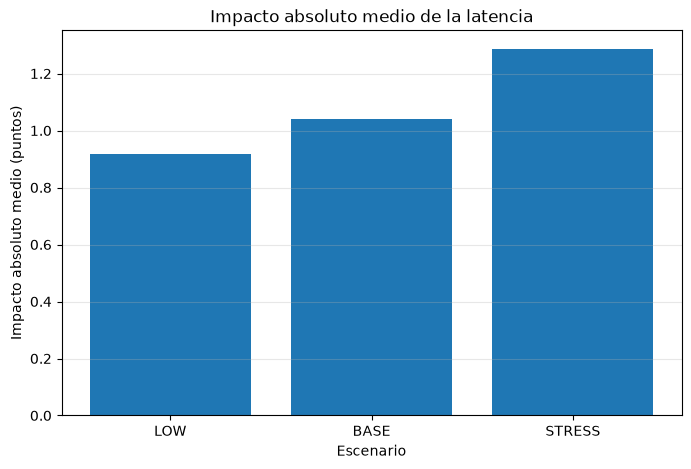

In [27]:
plt.figure(
    figsize=(8, 5)
)


plt.bar(
    latency_summary[
        "scenario"
    ],

    latency_summary[
        "mean_abs_impact_points"
    ]
)


plt.title(
    "Impacto absoluto medio de la latencia"
)

plt.xlabel(
    "Escenario"
)

plt.ylabel(
    "Impacto absoluto medio (puntos)"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

## Distribución BASE

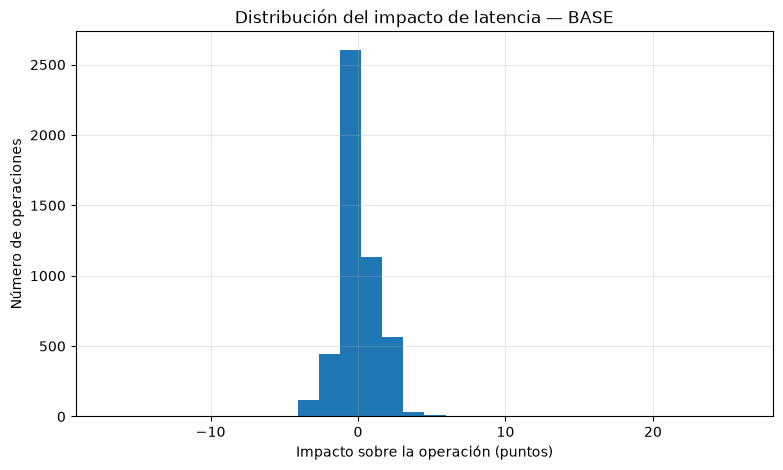

In [28]:
plt.figure(
    figsize=(9, 5)
)


plt.hist(
    base_latency_results[
        "latency_impact_points"
    ],
    bins=30
)


plt.title(
    "Distribución del impacto de latencia — BASE"
)

plt.xlabel(
    "Impacto sobre la operación (puntos)"
)

plt.ylabel(
    "Número de operaciones"
)

plt.grid(
    alpha=0.3
)

plt.show()

## 20. Combinar latencia y slippage

La secuencia conceptual de una ejecución realista será:

1. se genera una señal;
2. conocemos Bid/Ask;
3. comprobamos el spread;
4. enviamos la orden;
5. transcurre la latencia;
6. llegamos a una nueva cotización;
7. sobre ese precio puede producirse slippage;
8. obtenemos el precio finalmente ejecutado.

Por tanto:

Bid/Ask
→ latencia
→ precio disponible posteriormente
→ slippage
→ precio ejecutado

In [29]:
def apply_slippage(
    expected_price,
    action,
    slippage_points
):
    """
    Convención Fase 5:

    slippage positivo = adverso.
    slippage negativo = favorable.
    """

    action = (
        action.upper()
    )


    price_delta = (
        float(
            slippage_points
        )
        *
        POINT
    )


    if action == "BUY":

        return float(
            expected_price
            +
            price_delta
        )


    elif action == "SELL":

        return float(
            expected_price
            -
            price_delta
        )


    else:

        raise ValueError(
            "action debe ser BUY o SELL."
        )

## Añadir slippage a una operación con latencia

In [30]:
def add_fixed_slippage_to_latency_trade(
    latency_trade,
    entry_slippage_points,
    exit_slippage_points
):
    """
    Añade slippage conocido a una operación
    previamente simulada con latencia.
    """

    if (
        latency_trade[
            "status"
        ]
        !=
        "EXECUTED"
    ):

        raise ValueError(
            "La operación con latencia "
            "debe estar ejecutada."
        )


    direction = (
        latency_trade[
            "direction"
        ]
    )


    entry_action = (
        latency_trade[
            "entry_action"
        ]
    )


    exit_action = (
        latency_trade[
            "exit_action"
        ]
    )


    entry_price_latency = (
        latency_trade[
            "latency_entry_price"
        ]
    )


    exit_price_latency = (
        latency_trade[
            "latency_exit_price"
        ]
    )


    final_entry_price = (
        apply_slippage(
            expected_price=
                entry_price_latency,

            action=
                entry_action,

            slippage_points=
                entry_slippage_points
        )
    )


    final_exit_price = (
        apply_slippage(
            expected_price=
                exit_price_latency,

            action=
                exit_action,

            slippage_points=
                exit_slippage_points
        )
    )


    if direction == "BUY":

        pnl_final_price = (
            final_exit_price
            -
            final_entry_price
        )

    else:

        pnl_final_price = (
            final_entry_price
            -
            final_exit_price
        )


    pnl_final_points = (
        pnl_final_price
        /
        POINT
    )


    pnl_latency_points = (
        latency_trade[
            "pnl_latency_points"
        ]
    )


    pnl_no_latency_points = (
        latency_trade[
            "pnl_no_latency_points"
        ]
    )


    slippage_impact_points = (
        pnl_latency_points
        -
        pnl_final_points
    )


    total_impact_points = (
        pnl_no_latency_points
        -
        pnl_final_points
    )


    expected_total_impact = (
        latency_trade[
            "latency_impact_points"
        ]
        +
        slippage_impact_points
    )


    assert np.isclose(
        total_impact_points,
        expected_total_impact,
        atol=1e-6
    )


    return {
        "direction":
            direction,

        "pnl_no_latency_no_slippage":
            pnl_no_latency_points,

        "pnl_with_latency":
            pnl_latency_points,

        "pnl_with_latency_and_slippage":
            pnl_final_points,

        "latency_impact_points":
            latency_trade[
                "latency_impact_points"
            ],

        "slippage_impact_points":
            slippage_impact_points,

        "total_impact_points":
            total_impact_points,

        "final_entry_price":
            final_entry_price,

        "final_exit_price":
            final_exit_price
    }

## Comprobar la descomposición de costes

Con esto estamos construyendo la relación:

Coste/desviación total de ejecución

= efecto de latencia
+
efecto de slippage

In [31]:
if (
    trade_fixed_latency[
        "status"
    ]
    ==
    "EXECUTED"
):

    combined_example = (
        add_fixed_slippage_to_latency_trade(
            latency_trade=
                trade_fixed_latency,

            entry_slippage_points=1,

            exit_slippage_points=2
        )
    )


    display(
        pd.DataFrame(
            [combined_example]
        ).T
    )


    print(
        "\nImpacto latencia:",
        combined_example[
            "latency_impact_points"
        ]
    )

    print(
        "Impacto slippage:",
        combined_example[
            "slippage_impact_points"
        ]
    )

    print(
        "Impacto total:",
        combined_example[
            "total_impact_points"
        ]
    )

,0
direction,BUY
pnl_no_latency_no_slippage,-2.0
pnl_with_latency,-1.0
pnl_with_latency_and_slippage,-4.0
latency_impact_points,-1.0
slippage_impact_points,3.0
total_impact_points,2.0
final_entry_price,1.16173
final_exit_price,1.16169



Impacto latencia: -0.9999999999843465
Impacto slippage: 2.999999999997449
Impacto total: 2.0000000000131024


## 21. Medición futura de latencia real

Los escenarios actuales son simulados.

Durante el forward test debemos registrar información real de cada
orden.

Como mínimo:

- identificador de la orden;
- símbolo;
- BUY / SELL;
- volumen;
- precio solicitado;
- precio ejecutado;
- spread en el momento de envío;
- instante de envío;
- instante de respuesta;
- tiempo de ida y vuelta;
- slippage observado;
- hora del servidor;
- hora UTC correctamente normalizada.

También intentaremos incorporar posteriormente:

- proximidad a NFP;
- proximidad a CPI;
- proximidad a FOMC;
- proximidad a decisiones del BCE;
- período de rollover;
- volatilidad;
- tamaño de posición;
- broker;
- infraestructura utilizada.

IMPORTANTE:

No se debe calcular una latencia mezclando directamente dos relojes
distintos sin comprobar previamente su sincronización.

Para medir duraciones será preferible utilizar un reloj monotónico de
alta resolución en el mismo sistema que envía y recibe la orden.

Después podremos estudiar estadísticamente relaciones como:

latencia → slippage

spread → slippage

noticias → latencia/slippage

rollover → spread/slippage

volumen → slippage

Esto incorpora lo que acordamos sobre las defensas futuras contra malas ejecuciones.

## 22. Resumen de la Fase 6

In [32]:
phase6_summary = pd.DataFrame(
    [
        {
            "concepto":
                "Ticks disponibles",

            "valor":
                len(ticks_exec)
        },

        {
            "concepto":
                "P99 spread",

            "valor":
                spread_p99
        },

        {
            "concepto":
                "Latencia = 0",

            "valor":
                "reproduce ejecución inmediata"
        },

        {
            "concepto":
                "Latencia simulada",

            "valor":
                "LOW / BASE / STRESS"
        },

        {
            "concepto":
                "Precio después de latencia",

            "valor":
                "primer tick posterior al tiempo objetivo"
        },

        {
            "concepto":
                "Impacto positivo",

            "valor":
                "desfavorable"
        },

        {
            "concepto":
                "Impacto negativo",

            "valor":
                "favorable"
        },

        {
            "concepto":
                "Latencia real broker",

            "valor":
                "NO medida todavía"
        },

        {
            "concepto":
                "Slippage",

            "valor":
                "compatible con Fase 5"
        }
    ]
)


display(
    phase6_summary
)

,concepto,valor
0,Ticks disponibles,1064157
1,P99 spread,2.0
2,Latencia = 0,reproduce ejecución inmediata
3,Latencia simulada,LOW / BASE / STRESS
4,Precio después de latencia,primer tick posterior al tiempo objetivo
5,Impacto positivo,desfavorable
6,Impacto negativo,favorable
7,Latencia real broker,NO medida todavía
8,Slippage,compatible con Fase 5


# Conclusión de la Fase 6

En esta fase incorporamos el tiempo al modelo de ejecución.

Hasta ahora conocíamos el precio disponible en el instante de decisión.

Ahora simulamos que la orden necesita un determinado número de
milisegundos antes de alcanzar el mercado.

La ejecución se realiza utilizando el primer tick disponible después
de ese retraso.

Esto permite distinguir claramente:

Spread:
diferencia entre Ask y Bid.

Slippage:
diferencia entre el precio esperado y el finalmente ejecutado.

Latencia:
tiempo transcurrido entre la decisión y la posibilidad de ejecución.

El efecto de la latencia no tiene por qué ser siempre negativo.

Durante el retraso el mercado puede:

- moverse en contra;
- permanecer igual;
- moverse a favor.

Por ello analizamos tanto:

- impacto firmado;
- impacto absoluto.

También dejamos preparado el modelo para combinar:

Bid / Ask
→ spread
→ filtro de ejecución
→ latencia
→ slippage

Los escenarios actuales de latencia son simulados.

Más adelante serán calibrados mediante datos obtenidos durante el
forward test en MT5.

La siguiente fase será:

`07_atr_volatility.ipynb`